<a href="https://colab.research.google.com/github/jsmak/mytransformer/blob/main/notebooks/06_PositionalEncoding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **PositionalEncoding**
이 셀은 Transformer 모델에서 사용되는 `PositionalEncoding` 클래스를 정의합니다.  
이 클래스는 입력 시퀀스의 각 토큰에 위치 정보를 주입하기 위해 사인(sin) 및 코사인(cos) 함수를 사용하여 위치 인코딩을 생성합니다.   
`d_model`은 모델의 임베딩 차원을 나타내고, `max_len`은 최대 시퀀스 길이를 지정합니다.

$$PE_{(pos, 2i)} = \sin(pos / 10000^{2i/d_{model}})$$
$$PE_{(pos, 2i+1)} = \cos(pos / 10000^{2i/d_{model}})$$

여기서:
- $pos$는 토큰의 위치를 나타냅니다.
- $i$는 임베딩 차원의 인덱스를 나타냅니다.
- $d_{model}$은 모델의 임베딩 차원입니다.

이 수식을 통해 각 위치마다 고유한 패턴의 위치 인코딩이 생성되며, 이는 시퀀스의 상대적인 위치 정보를 모델에 제공합니다.

In [2]:
import torch
import torch.nn as nn

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()

        self.pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)

        div_term = 1.0 / (10000.0 ** (torch.arange(0, d_model, 2).float() / d_model))

        self.pe[:, 0::2] = torch.sin(position * div_term)
        self.pe[:, 1::2] = torch.cos(position * div_term)
        self.pe = self.pe.unsqueeze(0) # shape를 (1,max_len, emb_dim) 으로 변환

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :] # 문장의 길이 만큼만 추출해서 더함

### PositionalEncoding 적용 및 텐서 Shape 확인
이 셀은 정의된 `PositionalEncoding` 클래스를 실제로 사용하는 방법을 보여줍니다.   
- `batch_size`, `seq_len`, `d_model`을 사용하여 랜덤 텐서 `x`를 생성하고, 여기에 위치 인코딩을 적용하여 `encoded_x`를 얻습니다.   
- 각 텐서의 `shape`을 출력하여 데이터의 흐름과 차원 변화를 확인할 수 있습니다.

In [26]:
import torch

batch_size = 8
seq_len = 50
d_model = 512

x = torch.randn(batch_size, seq_len, d_model)
print("입력 shape:", x.shape)
positional_encoding = PositionalEncoding(d_model, seq_len)
pe = positional_encoding.pe.squeeze().cpu().detach().numpy()
print("PE shape:", pe.shape)

encoded_x = positional_encoding(x)
print("입력 + PE shape:", encoded_x.shape)
encoded_x.cpu().detach().numpy().round(3)

입력 shape: torch.Size([8, 50, 512])
PE shape: (50, 512)
입력 + PE shape: torch.Size([8, 50, 512])


array([[[ 7.230e-01,  1.680e-01, -2.100e-02, ...,  8.460e-01,
          7.500e-01, -9.040e-01],
        [-1.159e+00, -8.050e-01,  1.720e+00, ...,  3.470e-01,
          1.383e+00,  6.410e-01],
        [ 9.960e-01, -3.200e-02,  1.861e+00, ...,  1.171e+00,
         -1.156e+00, -1.480e-01],
        ...,
        [-1.540e-01, -1.200e+00, -1.660e-01, ...,  7.870e-01,
         -8.170e-01,  2.670e-01],
        [-1.532e+00,  6.100e-02,  1.189e+00, ...,  1.664e+00,
          2.170e-01,  1.291e+00],
        [-6.070e-01,  4.510e-01, -1.400e+00, ...,  1.495e+00,
          3.140e-01,  1.610e-01]],

       [[-2.650e-01, -3.270e-01, -9.250e-01, ..., -8.600e-02,
          9.020e-01,  1.450e-01],
        [ 7.890e-01,  4.710e-01, -2.670e-01, ...,  1.266e+00,
          2.100e-01,  1.800e-01],
        [ 7.090e-01, -4.260e-01,  1.583e+00, ...,  2.120e+00,
         -1.920e-01,  1.544e+00],
        ...,
        [ 4.790e-01, -1.427e+00,  1.499e+00, ...,  7.950e-01,
         -9.990e-01,  1.055e+00],
        [ 5.

### **입력(x), 위치 인코딩(pe), 인코딩된 입력(encoded_x) 시각화**
이 셀은 입력 텐서 `x`, 생성된 위치 인코딩 `pe`, 그리고 `x`에 `pe`가 더해진 `encoded_x`를 `imshow()` 함수를 사용하여 시각적으로 보여줍니다.   
이를 통해 각 텐서 내부의 패턴과 위치 인코딩이 입력에 어떻게 더해지는지 직관적으로 이해할 수 있습니다.   
`x`는 랜덤으로 생성되었으며, `pe`는 고유한 주기적인 패턴을 가집니다.
encoding_x에 pe패턴이 살짝 나타나는것을 확인할 수 있습니다.

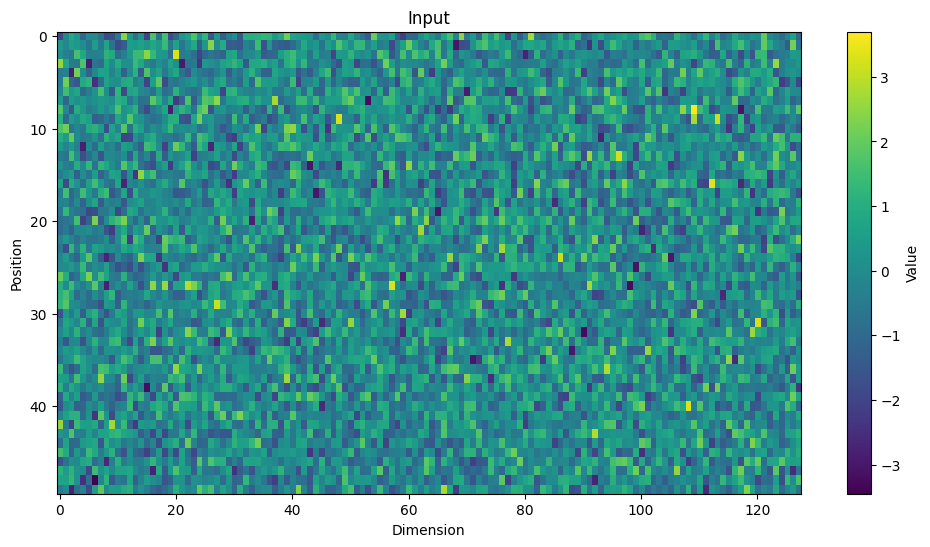

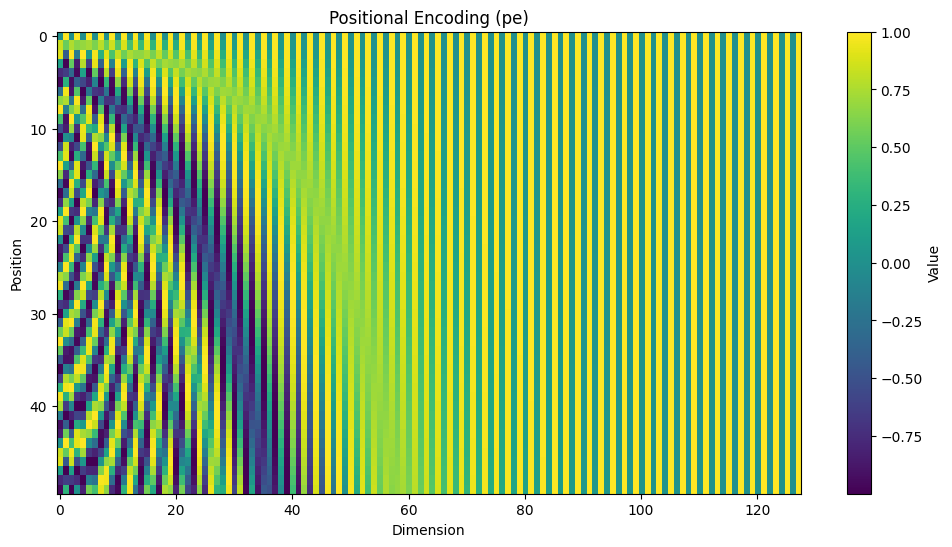

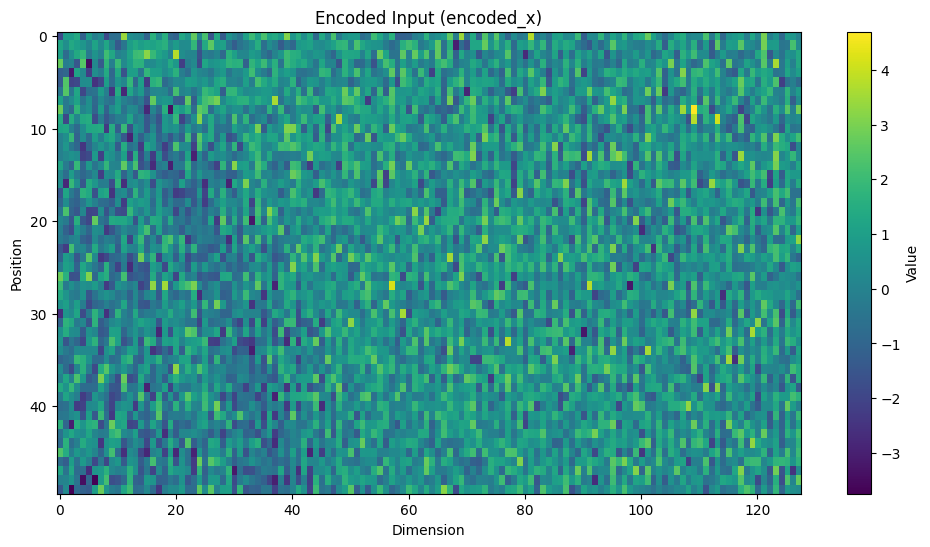

In [27]:
import torch
import matplotlib.pyplot as plt

d_model = 128
seq_len = 50

x = torch.randn(1, seq_len, d_model)
input = x.squeeze()

plt.figure(figsize=(12, 6))
plt.imshow(input, cmap='viridis', aspect='auto')
plt.title('Input')
plt.xlabel('Dimension')
plt.ylabel('Position')
plt.colorbar(label='Value')
plt.show()

pos_enc = PositionalEncoding(d_model, max_len=seq_len)
pe = pos_enc.pe.squeeze().cpu().detach().numpy()

plt.figure(figsize=(12, 6))
plt.imshow(pe, cmap='viridis', aspect='auto')
plt.title('Positional Encoding (pe)')
plt.xlabel('Dimension')
plt.ylabel('Position')
plt.colorbar(label='Value')
plt.show()

encoded_x = pos_enc(x)

plt.figure(figsize=(12, 6))
plt.imshow(encoded_x.squeeze().cpu().detach().numpy(), cmap='viridis', aspect='auto')
plt.title('Encoded Input (encoded_x)')
plt.xlabel('Dimension')
plt.ylabel('Position')
plt.colorbar(label='Value')
plt.show()
